## Imports

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Data

In [8]:
df = pd.read_csv('../data/raw/diabetic_data.csv', na_values='?', dtype={'payer_code': str})

## Inspect First Few Rows
Gather General Info

In [9]:
display(df.head())
print(df.info())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

## Analyze Missing Values

In [10]:
missing_percentages = (df.isnull().sum() / len(df)) * 100
missing_features = missing_percentages[missing_percentages > 0].sort_values(ascending=False)

print('\nFeatures with missing values (>0%):')
print(missing_features)


Features with missing values (>0%):
weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64


## Plot missing values

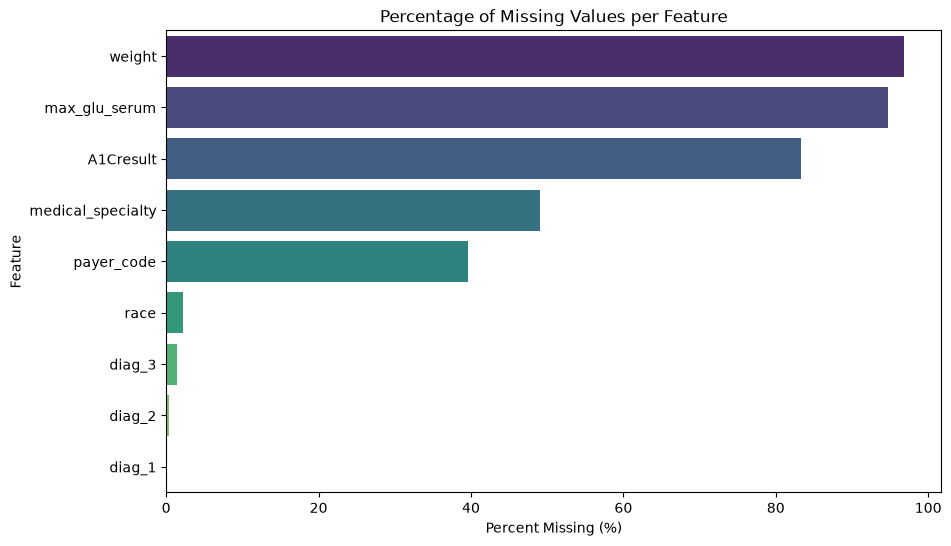

In [16]:
plt.figure(figsize=(10,6))
sns.barplot(x=missing_features.values, y=missing_features.index, hue=missing_features.index, palette='viridis', legend=False)
plt.title('Percentage of Missing Values per Feature')
plt.xlabel('Percent Missing (%)')
plt.ylabel('Feature')
plt.show()

## Analyze Target Variable (readmitted)
Classes are: '<30' (readmitted in less than 30 days), '>30', and 'NO'

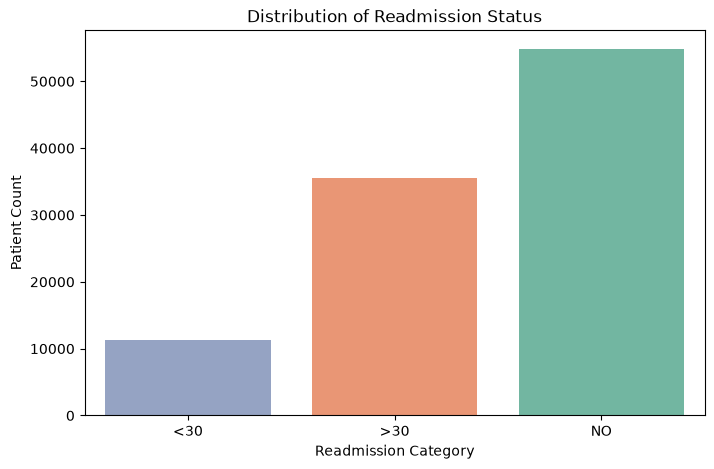


Target Variable Distribution:
readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64


In [20]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='readmitted', hue='readmitted', order=['<30', '>30', 'NO'], palette='Set2', legend=False)
plt.title('Distribution of Readmission Status')
plt.ylabel('Patient Count')
plt.xlabel('Readmission Category')
plt.show()

print('\nTarget Variable Distribution:')
print(df['readmitted'].value_counts(normalize=True) * 100)
